# Rural fires in Portuguese municipalities

This report studies rural-fire frequency, alert sources, and emergency response in Alij?, Mirandela, Alc?cer do Sal, and Odemira. The comparison periods are 2014?2016 and 2018?2020; 2017 is excluded as a transition year.

The planned tests are Welch's t-test for monthly counts, Welch's ANOVA for response time, a chi-square test for alert source, and a two-proportion comparison for the `Populares` alert category (the general-public category recorded by the dataset).


In [1]:
from pathlib import Path
import unicodedata
from itertools import combinations
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

ALPHA = 0.05
MUNICIPALITIES = ['Alijó', 'Mirandela', 'Alcácer do Sal', 'Odemira']
YEARS = [2014, 2015, 2016, 2018, 2019, 2020]
PRE, POST = '2014-2016', '2018-2020'
DATA_PATH_CANDIDATES = [
    Path('13-Registos-Incendios-SGIF-2011-2020') / 'Registos_Incendios_SGIF_2011_2020.xlsx',
    Path('Registos_Incendios_SGIF_2011_2020.xlsx'),
]
DATA_PATH = next((p for p in DATA_PATH_CANDIDATES if p.is_file()), None)
if DATA_PATH is None:
    raise FileNotFoundError('Place the SGIF Excel next to this notebook, or edit DATA_PATH_CANDIDATES.')
print('Using dataset:', DATA_PATH.resolve())

Using dataset: C:\Users\HP\Desktop\FEUP\FCED\Stats\Trabalho\Statistics-FCED\13-Registos-Incendios-SGIF-2011-2020\Registos_Incendios_SGIF_2011_2020.xlsx


In [2]:
fires = pd.read_excel(DATA_PATH, sheet_name='SGIF_2011_2020')
print(f'Full dataset: {fires.shape[0]:,} rows and {fires.shape[1]} columns')
fires.head()


Full dataset: 177,129 rows and 41 columns


,Codigo_SGIF,Codigo_ANEPC,Ano,Mes,Dia,Hora,AreaPov_ha,AreaMato_ha,AreaAgric_ha,AreaTotal_ha,...,ISI,DC,DMC,FFMC,BUI,CodCausa,TipoCausa,GrupoCausa,DescricaoCausa,FonteAlerta
0,DM2111,368,2011,1,1,17,0.0,0.010,0.00000,0.01000,...,0.291930,4.092373,0.653638,54.525424,0.934234,145.0,Negligente,Uso do fogo - Fogueiras,Fogueiras - Outras,Populares
1,BL4112,1236,2011,1,9,22,0.0,0.000,0.00200,0.00200,...,0.013831,1.835452,0.367371,32.001278,0.489703,610.0,Desconhecida,Indeterminadas,Indeterminadas - Prova material,Populares
2,DM3111,820,2011,1,15,17,0.0,0.000,0.00001,0.00001,...,1.171990,9.658571,1.573768,74.889775,2.236498,124.0,Negligente,Queimas amontoados de sobrantes florestais ou ...,Queima de amontoados - Borralheiras,Populares
3,BL2111,1977,2011,1,18,22,0.0,0.001,0.00000,0.00100,...,0.248910,12.477199,0.762519,51.102608,1.322920,124.0,Negligente,Queimas amontoados de sobrantes florestais ou ...,Queima de amontoados - Borralheiras,Populares
4,DM2113,7930,2011,1,19,17,0.0,0.005,0.00000,0.00500,...,0.008092,3.968661,0.508191,32.290416,0.769912,NaN,NaN,NaN,NaN,Populares


## Data preparation

The workbook contains accent and capitalization variants in municipality names. Matching therefore uses an accent-insensitive key while preserving canonical names in the output.


In [3]:
USE_COLS = ['Codigo_SGIF','Concelho','Ano','Mes','AreaTotal_ha','FWI',
            'DataHoraAlerta','DataHora_PrimeiraIntervencao','FonteAlerta','GrupoCausa']
fires = pd.read_excel(DATA_PATH, sheet_name='SGIF_2011_2020', usecols=USE_COLS)
print('Records in source:', len(fires))

def normalize_text(value):
    if pd.isna(value):
        return ''
    txt = unicodedata.normalize('NFKD', str(value))
    return ''.join(ch for ch in txt if not unicodedata.combining(ch)).casefold().strip()

mun_map = {normalize_text(m): m for m in MUNICIPALITIES}
fires['Municipio'] = fires['Concelho'].map(lambda x: mun_map.get(normalize_text(x)))
df = fires.loc[fires['Municipio'].notna() & fires['Ano'].isin(YEARS)].copy()
df['Periodo'] = np.where(df['Ano'] <= 2016, PRE, POST)
df['Mes'] = pd.to_numeric(df['Mes'], errors='coerce')
for column in ['DataHoraAlerta','DataHora_PrimeiraIntervencao']:
    df[column] = pd.to_datetime(df[column], errors='coerce')
df['TempoPrimeiraIntervencao_min'] = (
    (df['DataHora_PrimeiraIntervencao'] - df['DataHoraAlerta']).dt.total_seconds() / 60
)
invalid_response = df['TempoPrimeiraIntervencao_min'].isna() | (df['TempoPrimeiraIntervencao_min'] < 0)
df.loc[invalid_response, 'TempoPrimeiraIntervencao_min'] = np.nan

# Standardise text to compare accents, casing, and accidental whitespace.
df['FonteAlerta_key'] = df['FonteAlerta'].map(normalize_text)
df.loc[df['FonteAlerta_key'].eq(''), 'FonteAlerta_key'] = np.nan
PUBLIC_KEY = normalize_text('Populares')

print('Selected records:', len(df))
print('Invalid/missing response:', int(invalid_response.sum()))
print('Missing alert source:', int(df['FonteAlerta_key'].isna().sum()))
print('Missing cause group:', int(df['GrupoCausa'].isna().sum()))
print('Duplicate SGIF IDs:', int(df['Codigo_SGIF'].duplicated().sum()))
print('Month outside 1..12:', int((~df['Mes'].between(1, 12)).sum()))
print('Largest response times (check data quality):')
display(df[['Municipio','Ano','DataHoraAlerta','DataHora_PrimeiraIntervencao',
            'TempoPrimeiraIntervencao_min']].nlargest(10,'TempoPrimeiraIntervencao_min'))
display(df.groupby(['Municipio','Periodo']).size().unstack(fill_value=0))

Records in source: 177129
Selected records: 884
Invalid/missing response: 2
Missing alert source: 0
Missing cause group: 37
Duplicate SGIF IDs: 0
Month outside 1..12: 0
Largest response times (check data quality):


,Municipio,Ano,DataHoraAlerta,DataHora_PrimeiraIntervencao,TempoPrimeiraIntervencao_min
83494,Alcácer do Sal,2014,2014-07-28 20:03:00,2014-07-28 22:23:00,140.0
156615,Mirandela,2018,2018-11-19 18:14:00,2018-11-19 20:20:00,126.0
163703,Odemira,2019,2019-08-19 11:28:00,2019-08-19 13:04:00,96.0
176720,Odemira,2020,2020-10-16 16:30:00,2020-10-16 17:55:00,85.0
157347,Odemira,2019,2019-02-24 18:54:00,2019-02-24 20:18:00,84.0
148152,Mirandela,2018,2018-05-13 20:08:00,2018-05-13 21:30:00,82.0
157117,Odemira,2019,2019-02-09 19:32:00,2019-02-09 20:54:00,82.0
93828,Odemira,2015,2015-06-04 05:21:00,2015-06-04 06:32:00,71.0
177010,Odemira,2020,2020-11-04 03:10:00,2020-11-04 04:21:00,71.0
147328,Alijó,2018,2018-05-03 14:12:00,2018-05-03 15:20:00,68.0


Periodo,2014-2016,2018-2020
Municipio,,
Alcácer do Sal,85,70
Alijó,116,71
Mirandela,186,115
Odemira,128,113


## Descriptive statistics and plots


Occurrences  Mean_burned_area_ha  \
Municipio      Periodo                                       
Alcácer do Sal 2014-2016           85                 1.66   
               2018-2020           70                 0.72   
Alijó          2014-2016          116                 8.82   
               2018-2020           71                31.40   
Mirandela      2014-2016          186                 1.41   
               2018-2020          115                 7.97   
Odemira        2014-2016          128                 7.32   
               2018-2020          113                 3.51   

                          Median_burned_area_ha  Mean_FWI  Mean_response_min  \
Municipio      Periodo                                                         
Alcácer do Sal 2014-2016                   0.05     27.66              17.79   
               2018-2020                   0.13     26.60              18.93   
Alijó          2014-2016                   0.15     19.35              18.16   
               2018-2020                   0.20     16.71              17.11   
Mirandela      2014-2016                   0.11     24.70              11.00   
               2018-2020                   0.15     21.32              15.45   
Odemira        2014-2016                   0.20     28.52              22.18   
               2018-2020                   0.13     21.68              24.75   

                          Median_response_min  Valid_responses  
Municipio      Periodo                                          
Alcácer do Sal 2014-2016                 15.0               85  
               2018-2020                 15.5               70  
Alijó          2014-2016                 15.0              116  
               2018-2020                 14.0               70  
Mirandela      2014-2016                  8.0              186  
               2018-2020                 13.0              115  
Odemira        2014-2016                 18.5              128  
               2018-2020                 21.0              112

Monthly observations by period:


,Monthly observations
Periodo,
2014-2016,144
2018-2020,144


Zero-months: 90


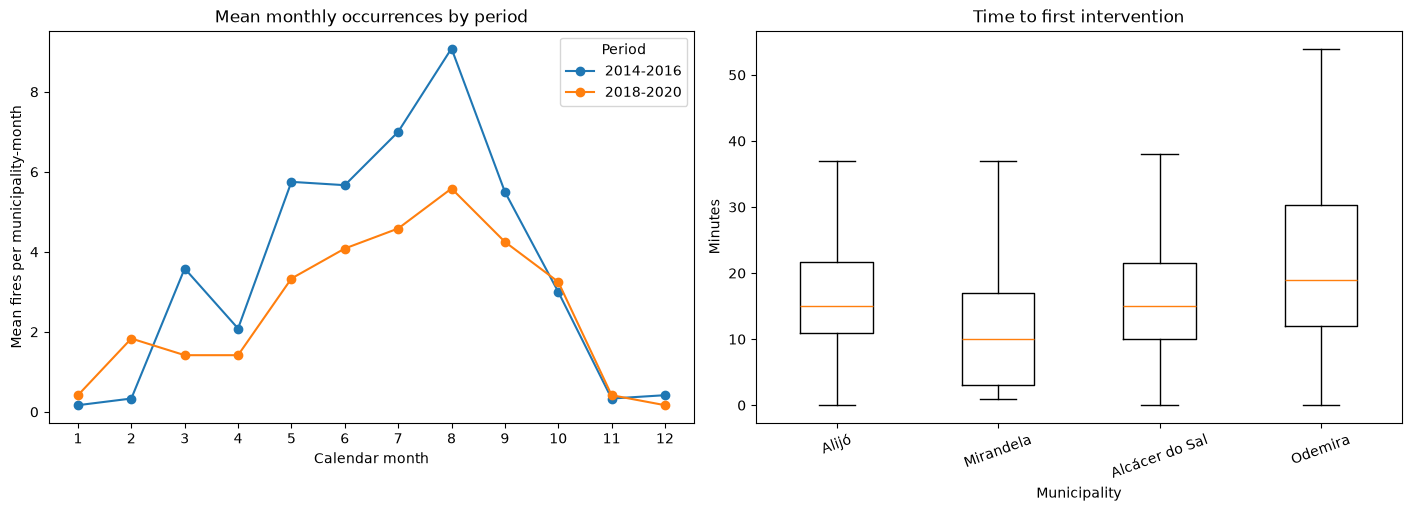

In [4]:

# --------------------------------------------------
# DESCRIPTIVE STATISTICS
# --------------------------------------------------

summary = df.groupby(
    ['Municipio', 'Periodo']
).agg(
    Occurrences=(
        'Codigo_SGIF', 'size'
    ),
    Mean_burned_area_ha=(
        'AreaTotal_ha', 'mean'
    ),
    Median_burned_area_ha=(
        'AreaTotal_ha', 'median'
    ),
    Mean_FWI=(
        'FWI', 'mean'
    ),
    Mean_response_min=(
        'TempoPrimeiraIntervencao_min', 'mean'
    ),
    Median_response_min=(
        'TempoPrimeiraIntervencao_min', 'median'
    ),
    Valid_responses=(
        'TempoPrimeiraIntervencao_min', 'count'
    )
)

display(summary.round(2))


# --------------------------------------------------
# COMPLETE MONTHLY COUNTS
# --------------------------------------------------

# NEW: include months with zero recorded fires

calendar = pd.MultiIndex.from_product(
    [
        MUNICIPALITIES,
        YEARS,
        range(1, 13)
    ],
    names=['Municipio', 'Ano', 'Mes']
)

monthly_counts = (
    df.groupby(['Municipio', 'Ano', 'Mes'])
    .size()
    .reindex(calendar, fill_value=0)
    .rename('Ocorrencias')
    .reset_index()
)

monthly_counts['Periodo'] = np.where(
    monthly_counts['Ano'] <= 2016,
    PRE,
    POST
)

print('Monthly observations by period:')

display(
    monthly_counts.groupby('Periodo')
    .size()
    .rename('Monthly observations')
    .to_frame()
)

print('Zero-months:', int(
    (monthly_counts['Ocorrencias'] == 0).sum()
))


# --------------------------------------------------
# ORIGINAL TWO-PANEL VISUALIZATION
# --------------------------------------------------

fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 5),
    constrained_layout=True
)

# Chart 1 — monthly occurrences
monthly_pattern = (
    monthly_counts.groupby(
        ['Periodo', 'Mes']
    )['Ocorrencias']
    .mean()
    .unstack('Periodo')
    .reindex(columns=[PRE, POST])
)

monthly_pattern.plot(
    ax=axes[0],
    marker='o'
)

axes[0].set(
    title='Mean monthly occurrences by period',
    xlabel='Calendar month',
    ylabel='Mean fires per municipality-month'
)

axes[0].set_xticks(range(1, 13))
axes[0].legend(title='Period')


# Chart 2 — response times by municipality
response_plot_data = [
    df.loc[
        df['Municipio'].eq(m),
        'TempoPrimeiraIntervencao_min'
    ].dropna().to_numpy()
    for m in MUNICIPALITIES
]

axes[1].boxplot(
    response_plot_data,
    tick_labels=MUNICIPALITIES,
    showfliers=False
)

axes[1].set(
    title='Time to first intervention',
    xlabel='Municipality',
    ylabel='Minutes'
)

axes[1].tick_params(
    axis='x',
    labelrotation=20
)

plt.show()


## Inference tests

The occurrence test compares the 144 municipality-month observations in each period. The response-time test excludes the missing intervention timestamp. Expected chi-square cell counts are displayed because small expected counts affect the reliability of the asymptotic approximation.


In [5]:

# --------------------------------------------------
# RQ1 — WELCH T-TEST FOR MONTHLY FIRE COUNTS
# --------------------------------------------------

# Separate monthly counts into the two periods
monthly_groups = [
    monthly_counts.loc[
        monthly_counts['Periodo'] == period,
        'Ocorrencias'
    ].to_numpy()
    for period in [PRE, POST]
]

pre_monthly, post_monthly = monthly_groups

# Check sample sizes
print('PRE sample size:', len(pre_monthly))
print('POST sample size:', len(post_monthly))

# Descriptive statistics
print('PRE mean:', pre_monthly.mean())
print('POST mean:', post_monthly.mean())

# Welch two-sample t-test
# Order: POST - PRE
occurrence_ttest = stats.ttest_ind(
    post_monthly,
    pre_monthly,
    equal_var=False
)

print('Welch t-test for monthly counts:')
print(occurrence_ttest)

# --------------------------------------------------
# 95% CONFIDENCE INTERVAL FOR MEAN DIFFERENCE
# --------------------------------------------------

mean_difference = (
    post_monthly.mean() - pre_monthly.mean()
)

v_post = (
    post_monthly.var(ddof=1)
    / len(post_monthly)
)

v_pre = (
    pre_monthly.var(ddof=1)
    / len(pre_monthly)
)

standard_error = np.sqrt(v_post + v_pre)

# Welch-Satterthwaite degrees of freedom
welch_df = (
    (v_post + v_pre)**2
    /
    (
        v_post**2 / (len(post_monthly) - 1)
        +
        v_pre**2 / (len(pre_monthly) - 1)
    )
)

# Critical t value
t_critical = stats.t.ppf(
    1 - ALPHA / 2,
    welch_df
)

# Confidence interval
ci_lower = mean_difference - t_critical * standard_error
ci_upper = mean_difference + t_critical * standard_error

print('Mean difference (POST - PRE):', mean_difference)
print('Welch degrees of freedom:', welch_df)
print('95% confidence interval:', (ci_lower, ci_upper))
print('p-value:', occurrence_ttest.pvalue)
print('Reject H0 at 5%:', occurrence_ttest.pvalue < ALPHA)


PRE sample size: 144
POST sample size: 144
PRE mean: 3.576388888888889
POST mean: 2.5625
Welch t-test for monthly counts:
TtestResult(statistic=np.float64(-2.318884606652698), pvalue=np.float64(0.021193442998756473), df=np.float64(254.63034901986546))
Mean difference (POST - PRE): -1.0138888888888888
Welch degrees of freedom: 254.63034901986558
95% confidence interval: (np.float64(-1.8749390339858403), np.float64(-0.15283874379193751))
p-value: 0.021193442998756473
Reject H0 at 5%: True


In [6]:

# --------------------------------------------------
# RQ2 — WELCH ANOVA FOR RESPONSE TIMES
# --------------------------------------------------

# Create one response-time sample per municipality
response_groups = [
    df.loc[
        df['Municipio'] == municipality,
        'TempoPrimeiraIntervencao_min'
    ].dropna().to_numpy()
    for municipality in MUNICIPALITIES
]

# Descriptive statistics
print('Response time summary by municipality:')

display(
    df.groupby('Municipio')[
        'TempoPrimeiraIntervencao_min'
    ]
    .agg(['count', 'mean', 'median', 'std'])
    .reindex(MUNICIPALITIES)
    .round(2)
)

# --------------------------------------------------
# WELCH ANOVA FUNCTION
# --------------------------------------------------

def welch_anova(groups):

    groups = [
        np.asarray(group, dtype=float)
        for group in groups
    ]

    # Remove missing and non-finite values
    groups = [
        group[np.isfinite(group)]
        for group in groups
    ]

    k = len(groups)

    sample_sizes = np.array(
        [len(group) for group in groups],
        dtype=float
    )

    if k < 3 or (sample_sizes < 2).any():
        raise ValueError(
            'At least 3 groups with 2 observations each are required.'
        )

    means = np.array([
        group.mean()
        for group in groups
    ])

    variances = np.array([
        group.var(ddof=1)
        for group in groups
    ])

    if (
        not np.isfinite(variances).all()
        or (variances <= 0).any()
    ):
        raise ValueError(
            'All groups must have positive finite variances.'
        )

    # Welch weights
    weights = sample_sizes / variances

    weighted_mean = (
        np.sum(weights * means)
        / np.sum(weights)
    )

    # Welch correction term
    correction_term = np.sum(
        (1 / (sample_sizes - 1))
        * (1 - weights / np.sum(weights)) ** 2
    )

    numerator = (
        np.sum(
            weights * (means - weighted_mean) ** 2
        )
        / (k - 1)
    )

    correction = (
        1
        +
        (2 * (k - 2) / (k**2 - 1))
        * correction_term
    )

    statistic = numerator / correction

    # Degrees of freedom
    numerator_df = k - 1

    denominator_df = (
        (k**2 - 1)
        / (3 * correction_term)
    )

    # p-value
    p_value = stats.f.sf(
        statistic,
        numerator_df,
        denominator_df
    )

    return (
        statistic,
        p_value,
        numerator_df,
        denominator_df
    )

# --------------------------------------------------
# EXECUTE WELCH ANOVA
# --------------------------------------------------

response_anova = welch_anova(response_groups)

print('Welch ANOVA for response time:')
print('F statistic:', response_anova[0])
print('p-value:', response_anova[1])
print('df1:', response_anova[2])
print('df2:', response_anova[3])
print('Reject H0 at 5%:', response_anova[1] < ALPHA)


Response time summary by municipality:


,count,mean,median,std
Municipio,,,,
Alijó,186,17.77,15.0,11.88
Mirandela,301,12.70,10.0,13.21
Alcácer do Sal,155,18.30,15.0,13.96
Odemira,240,23.38,19.0,16.37


Welch ANOVA for response time:
F statistic: 23.39760538430099
p-value: 4.58591437575806e-14
df1: 3
df2: 438.3353785254638
Reject H0 at 5%: True


Records with known alert source: 884
Records excluded: 0
Alert-source categories:


,Occurrences
FonteAlertaAgrupada,
populares,299
117,183
outros,137
112,120
pv,91
cco,54


Alert-source counts:


FonteAlertaAgrupada,112,117,cco,outros,populares,pv
Municipio,,,,,,
Alijó,33,43,18,15,59,19
Mirandela,46,42,26,35,99,53
Alcácer do Sal,41,9,0,19,83,3
Odemira,0,89,10,68,58,16


Chi-square statistic: 216.99102926415264
p-value: 7.338467756499568e-38
Degrees of freedom: 15
Smallest expected count: 9.468325791855204
Cells with expected count < 5: 0 out of 24
Reject H0 at 5%: True
Cramer's V: 0.2860448480168462
Alert-source percentages by municipality:


FonteAlertaAgrupada,112,117,cco,outros,populares,pv
Municipio,,,,,,
Alijó,17.65,22.99,9.63,8.02,31.55,10.16
Mirandela,15.28,13.95,8.64,11.63,32.89,17.61
Alcácer do Sal,26.45,5.81,0.00,12.26,53.55,1.94
Odemira,0.00,36.93,4.15,28.22,24.07,6.64


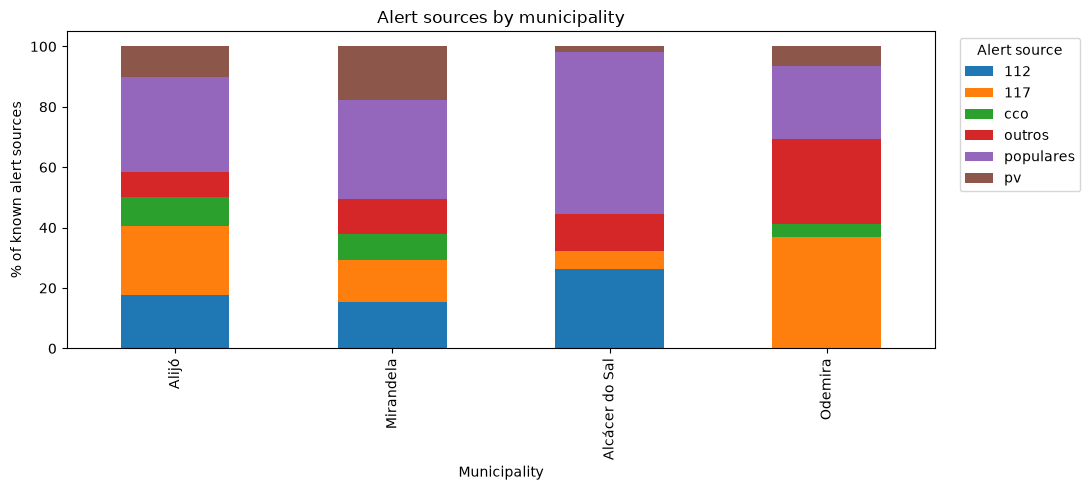

In [7]:

# --------------------------------------------------
# RQ3 — MUNICIPALITY AND ALERT SOURCE
# --------------------------------------------------

# Keep records with known alert sources
alerts = df.dropna(
    subset=['FonteAlerta_key']
).copy()

print('Records with known alert source:', len(alerts))
print('Records excluded:', len(df) - len(alerts))

# --------------------------------------------------
# GROUP RARE ALERT-SOURCE CATEGORY
# --------------------------------------------------

alerts['FonteAlertaAgrupada'] = (
    alerts['FonteAlerta_key'].replace({
        'sapadores': 'outros'
    })
)

print('Alert-source categories:')
display(
    alerts['FonteAlertaAgrupada']
    .value_counts()
    .to_frame('Occurrences')
)

# --------------------------------------------------
# CONTINGENCY TABLE
# --------------------------------------------------

alert_table = pd.crosstab(
    alerts['Municipio'],
    alerts['FonteAlertaAgrupada']
).reindex(
    MUNICIPALITIES,
    fill_value=0
)

print('Alert-source counts:')
display(alert_table)

# --------------------------------------------------
# CHI-SQUARE TEST
# --------------------------------------------------

chi_square = stats.chi2_contingency(
    alert_table,
    correction=False
)

expected = pd.DataFrame(
    chi_square.expected_freq,
    index=alert_table.index,
    columns=alert_table.columns
)

print('Chi-square statistic:', chi_square.statistic)
print('p-value:', chi_square.pvalue)
print('Degrees of freedom:', chi_square.dof)
print('Smallest expected count:', expected.min().min())

small_expected = int(
    (expected < 5).to_numpy().sum()
)

print(
    'Cells with expected count < 5:',
    small_expected,
    'out of',
    expected.size
)

print(
    'Reject H0 at 5%:',
    chi_square.pvalue < ALPHA
)

if small_expected > 0:
    print(
        'WARNING: Some expected counts are below 5. '
        'Review the chi-square approximation.'
    )

# --------------------------------------------------
# CRAMER'S V
# --------------------------------------------------

n = alert_table.to_numpy().sum()
r, c = alert_table.shape

cramers_v = np.sqrt(
    chi_square.statistic
    / (n * min(r - 1, c - 1))
)

print("Cramer's V:", cramers_v)

# --------------------------------------------------
# PERCENTAGES BY MUNICIPALITY
# --------------------------------------------------

alert_percentages = alert_table.div(
    alert_table.sum(axis=1),
    axis=0
) * 100

print('Alert-source percentages by municipality:')
display(alert_percentages.round(2))

# --------------------------------------------------
# STACKED BAR CHART
# --------------------------------------------------

ax = alert_percentages.plot.bar(
    stacked=True,
    figsize=(11, 5)
)

ax.set_title('Alert sources by municipality')
ax.set_xlabel('Municipality')
ax.set_ylabel('% of known alert sources')

ax.legend(
    title='Alert source',
    bbox_to_anchor=(1.02, 1),
    loc='upper left'
)

plt.tight_layout()
plt.show()


## 5. Burned area and cause classification

Two complementary variables are analyzed here: `AreaTotal_ha`, a quantitative measure of fire size, and `GrupoCausa`, a qualitative classification of the recorded cause. Because burned area is strongly right-skewed, the non-parametric Kruskal?Wallis test is used instead of ANOVA. Cause categories are grouped into the eight most frequent categories plus `Outros` to avoid an excessively sparse contingency table.


In [8]:

# --------------------------------------------------
# RQ4 — PUBLIC ALERT PROPORTIONS
# --------------------------------------------------

# Use the dataset with known alert sources
# created in Block 7

alerts['PublicAlert'] = (
    alerts['FonteAlerta_key'].eq(PUBLIC_KEY)
)

# --------------------------------------------------
# PUBLIC ALERT COUNTS AND PROPORTIONS
# --------------------------------------------------

public = (
    alerts.groupby('Periodo')['PublicAlert']
    .agg(['sum', 'count'])
    .reindex([PRE, POST])
)

public['non_public'] = (
    public['count'] - public['sum']
)

public['proportion'] = (
    public['sum'] / public['count']
)

print('Public-alert definition: Populares')
display(public)

# --------------------------------------------------
# PRE AND POST PROPORTIONS
# --------------------------------------------------

pre = public.loc[PRE]
post = public.loc[POST]

difference = (
    post['proportion'] - pre['proportion']
)

# --------------------------------------------------
# 95% CONFIDENCE INTERVAL
# --------------------------------------------------

# Unpooled standard error
se = np.sqrt(
    pre['proportion']
    * (1 - pre['proportion'])
    / pre['count']

    +

    post['proportion']
    * (1 - post['proportion'])
    / post['count']
)

z_critical = stats.norm.ppf(
    1 - ALPHA / 2
)

ci = (
    difference - z_critical * se,
    difference + z_critical * se
)

# --------------------------------------------------
# TWO-PROPORTION Z-TEST
# --------------------------------------------------

# Pooled proportion under H0
pooled = (
    pre['sum'] + post['sum']
) / (
    pre['count'] + post['count']
)

# Pooled standard error
pooled_se = np.sqrt(
    pooled * (1 - pooled)
    * (
        1 / pre['count']
        +
        1 / post['count']
    )
)

# Z statistic
z = difference / pooled_se

# Two-sided p-value
p_value = 2 * stats.norm.sf(abs(z))

# --------------------------------------------------
# RESULTS
# --------------------------------------------------

print('Post-minus-pre difference:', difference)
print('95% confidence interval:', ci)
print('Two-proportion Z statistic:', z)
print('Two-sided p-value:', p_value)
print('Reject H0 at 5%:', p_value < ALPHA)

# Check sample counts
print(
    'PRE public/non-public:',
    int(pre['sum']),
    int(pre['non_public'])
)

print(
    'POST public/non-public:',
    int(post['sum']),
    int(post['non_public'])
)

# --------------------------------------------------
# ADDITIONAL COMPARISON BY MUNICIPALITY
# --------------------------------------------------

municipality_public = (
    alerts.groupby(
        ['Municipio', 'Periodo']
    )['PublicAlert']
    .agg(['sum', 'count'])
)

municipality_public['proportion'] = (
    municipality_public['sum']
    / municipality_public['count']
)

print('Public-alert proportions by municipality:')
display(municipality_public.round(3))


Public-alert definition: Populares


,sum,count,non_public,proportion
Periodo,,,,
2014-2016,236,515,279,0.458252
2018-2020,63,369,306,0.170732


Post-minus-pre difference: -0.2875207198673928
95% confidence interval: (np.float64(-0.3451898022594544), np.float64(-0.22985163747533124))
Two-proportion Z statistic: -8.910427687050973
Two-sided p-value: 5.083607755460142e-19
Reject H0 at 5%: True
PRE public/non-public: 236 279
POST public/non-public: 63 306
Public-alert proportions by municipality:


sum  count  proportion
Municipio      Periodo                          
Alcácer do Sal 2014-2016   60     85       0.706
               2018-2020   23     70       0.329
Alijó          2014-2016   49    116       0.422
               2018-2020   10     71       0.141
Mirandela      2014-2016   93    186       0.500
               2018-2020    6    115       0.052
Odemira        2014-2016   34    128       0.266
               2018-2020   24    113       0.212

Burned-area summary by municipality:


,count,mean,median,std
Municipio,,,,
Alijó,187,17.40,0.18,98.17
Mirandela,301,3.91,0.12,26.01
Alcácer do Sal,155,1.24,0.08,3.90
Odemira,241,5.54,0.18,47.10


Kruskal-Wallis test for burned area: KruskalResult(statistic=np.float64(4.44065831626262), pvalue=np.float64(0.2176448998265229))
Reject H0 at 5%: False


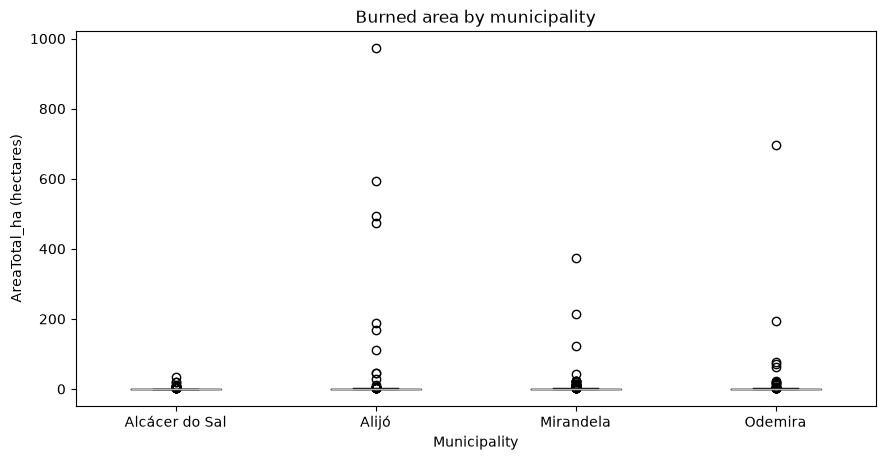

In [9]:

# --------------------------------------------------
# BURNED AREA BY MUNICIPALITY
# --------------------------------------------------

# Descriptive statistics
area_summary = (
    df.groupby('Municipio')['AreaTotal_ha']
    .agg(['count', 'mean', 'median', 'std'])
    .reindex(MUNICIPALITIES)
    .round(2)
)

# Create groups for Kruskal-Wallis
area_groups = [
    df.loc[
        df['Municipio'] == municipality,
        'AreaTotal_ha'
    ].dropna().to_numpy()
    for municipality in MUNICIPALITIES
]

# --------------------------------------------------
# KRUSKAL-WALLIS TEST
# --------------------------------------------------

area_test = stats.kruskal(*area_groups)

print('Burned-area summary by municipality:')
display(area_summary)

print(
    'Kruskal-Wallis test for burned area:',
    area_test
)

print(
    'Reject H0 at 5%:',
    area_test.pvalue < ALPHA
)

# --------------------------------------------------
# BOXPLOT
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(10, 5))

df.boxplot(
    column='AreaTotal_ha',
    by='Municipio',
    ax=ax,
    grid=False
)

ax.set_title('Burned area by municipality')
ax.set_xlabel('Municipality')
ax.set_ylabel('AreaTotal_ha (hectares)')

fig.suptitle('')
plt.show()


In [10]:

# --------------------------------------------------
# FIRE CAUSE GROUPS BY MUNICIPALITY
# --------------------------------------------------

# Keep only records with known cause groups
causes_df = df.dropna(
    subset=['GrupoCausa']
).copy()

print('Records with known cause:', len(causes_df))
print('Excluded missing causes:', len(df) - len(causes_df))

# --------------------------------------------------
# TOP 8 MOST FREQUENT CAUSE GROUPS
# --------------------------------------------------

top_causes = (
    causes_df['GrupoCausa']
    .value_counts()
    .head(8)
    .index
)

# Group less frequent causes into "Outros"
causes_df['GrupoCausaAgrupado'] = (
    causes_df['GrupoCausa'].where(
        causes_df['GrupoCausa'].isin(top_causes),
        'Outros'
    )
)

print('Most frequent cause groups:')

display(
    causes_df['GrupoCausaAgrupado']
    .value_counts()
    .to_frame('Ocorrencias')
)

# --------------------------------------------------
# CONTINGENCY TABLE
# --------------------------------------------------

cause_table = pd.crosstab(
    causes_df['Municipio'],
    causes_df['GrupoCausaAgrupado']
).reindex(
    MUNICIPALITIES,
    fill_value=0
)

print('Cause groups by municipality:')
display(cause_table)

# --------------------------------------------------
# CHI-SQUARE TEST
# --------------------------------------------------

cause_test = stats.chi2_contingency(
    cause_table,
    correction=False
)

print('Chi-square statistic:', cause_test.statistic)
print('p-value:', cause_test.pvalue)
print('Degrees of freedom:', cause_test.dof)
print(
    'Smallest expected count:',
    cause_test.expected_freq.min()
)

small_expected_causes = int(
    (cause_test.expected_freq < 5).sum()
)

print(
    'Cells with expected count < 5:',
    small_expected_causes,
    'out of',
    cause_test.expected_freq.size
)

print(
    'Reject H0 at 5%:',
    cause_test.pvalue < ALPHA
)

if small_expected_causes > 0:
    print(
        'WARNING: Some expected counts are below 5. '
        'Review the cause categories.'
    )

# --------------------------------------------------
# PERCENTAGES BY MUNICIPALITY
# --------------------------------------------------

cause_percentages = cause_table.div(
    cause_table.sum(axis=1),
    axis=0
) * 100

print('Cause percentages by municipality:')
display(cause_percentages.round(2))


Records with known cause: 847
Excluded missing causes: 37
Most frequent cause groups:


,Ocorrencias
GrupoCausaAgrupado,
Indeterminadas,259
Incendiarismo - Imputáveis,127
Queimadas de sobrantes florestais ou agrícolas,105
Queimas amontoados de sobrantes florestais ou agrícolas,94
Outros,81
Acidentais - Transportes e Comunicações,64
Acidentais - Maquinaria,58
Reacendimentos,30
Queimadas para gestão de pasto para gado,29


Cause groups by municipality:


GrupoCausaAgrupado,Acidentais - Maquinaria,Acidentais - Transportes e Comunicações,Incendiarismo - Imputáveis,Indeterminadas,Outros,Queimadas de sobrantes florestais ou agrícolas,Queimadas para gestão de pasto para gado,Queimas amontoados de sobrantes florestais ou agrícolas,Reacendimentos
Municipio,,,,,,,,,
Alijó,1,1,61,24,8,20,19,19,4
Mirandela,12,6,52,82,39,48,9,26,24
Alcácer do Sal,19,17,2,84,9,19,0,1,2
Odemira,26,40,12,69,25,18,1,48,0


Chi-square statistic: 340.6076382481474
p-value: 1.0212124909623383e-57
Degrees of freedom: 24
Smallest expected count: 5.238488783943329
Cells with expected count < 5: 0 out of 36
Reject H0 at 5%: True
Cause percentages by municipality:


GrupoCausaAgrupado,Acidentais - Maquinaria,Acidentais - Transportes e Comunicações,Incendiarismo - Imputáveis,Indeterminadas,Outros,Queimadas de sobrantes florestais ou agrícolas,Queimadas para gestão de pasto para gado,Queimas amontoados de sobrantes florestais ou agrícolas,Reacendimentos
Municipio,,,,,,,,,
Alijó,0.64,0.64,38.85,15.29,5.10,12.74,12.10,12.10,2.55
Mirandela,4.03,2.01,17.45,27.52,13.09,16.11,3.02,8.72,8.05
Alcácer do Sal,12.42,11.11,1.31,54.90,5.88,12.42,0.00,0.65,1.31
Odemira,10.88,16.74,5.02,28.87,10.46,7.53,0.42,20.08,0.00


## 6. Variables, hypotheses, and assumptions

**Qualitative variables:** `Municipio`, `Periodo`, `FonteAlerta`, and `GrupoCausa`. **Quantitative variables:** monthly occurrence count, `TempoPrimeiraIntervencao_min`, `AreaTotal_ha`, and `FWI`.

For each test, the null hypothesis states that there is no difference or association. A p-value below 0.05 is treated as evidence against the null hypothesis, but practical importance is evaluated using effect sizes and confidence intervals.


In [11]:
periods = sorted(df['Periodo'].dropna().unique())
pre_period, post_period = periods[0], periods[1]

pre_monthly = monthly_counts.loc[monthly_counts['Periodo'] == pre_period, 'Ocorrencias']
post_monthly = monthly_counts.loc[monthly_counts['Periodo'] == post_period, 'Ocorrencias']
mean_difference = post_monthly.mean() - pre_monthly.mean()
pooled_sd = np.sqrt(((len(pre_monthly) - 1) * pre_monthly.var(ddof=1) + (len(post_monthly) - 1) * post_monthly.var(ddof=1)) / (len(pre_monthly) + len(post_monthly) - 2))
cohens_d = mean_difference / pooled_sd
print('Period order:', pre_period, 'to', post_period)
print('Mean monthly occurrence difference (post - pre):', round(mean_difference, 2))
print("Cohen's d:", round(cohens_d, 2))
print('Levene test, monthly counts:', stats.levene(pre_monthly, post_monthly))
print('Levene test, response times:', stats.levene(*response_groups))


Period order: 2014-2016 to 2018-2020
Mean monthly occurrence difference (post - pre): -1.01
Cohen's d: -0.27
Levene test, monthly counts: LeveneResult(statistic=np.float64(6.734322549258087), pvalue=np.float64(0.009945365825622974))
Levene test, response times: LeveneResult(statistic=np.float64(5.130179113533401), pvalue=np.float64(0.0016029766181266919))


## 7. Post-hoc response-time comparisons

Since Welch ANOVA is significant, pairwise Welch t-tests identify which municipalities differ. The Holm correction controls the family-wise error rate across the six pairwise comparisons.


In [12]:

# --------------------------------------------------
# POST-HOC RESPONSE-TIME COMPARISONS
# --------------------------------------------------

response_by_municipality = {
    name: group[
        'TempoPrimeiraIntervencao_min'
    ].dropna().to_numpy()
    for name, group in df.groupby(
        'Municipio',
        sort=True
    )
}

# --------------------------------------------------
# PAIRWISE WELCH T-TESTS
# --------------------------------------------------

pairwise = []

for first, second in combinations(
    response_by_municipality,
    2
):

    group1 = response_by_municipality[first]
    group2 = response_by_municipality[second]

    result = stats.ttest_ind(
        group1,
        group2,
        equal_var=False
    )

    pairwise.append({
        'Municipio 1': first,
        'Municipio 2': second,
        'Mean difference (1-2)': (
            group1.mean() - group2.mean()
        ),
        't_statistic': result.statistic,
        'p_raw': result.pvalue
    })

# --------------------------------------------------
# SORT BY P-VALUE
# --------------------------------------------------

pairwise = (
    pd.DataFrame(pairwise)
    .sort_values('p_raw')
    .reset_index(drop=True)
)

# --------------------------------------------------
# HOLM CORRECTION
# --------------------------------------------------

m = len(pairwise)

holm_values = (
    pairwise['p_raw'].to_numpy()
    * (m - np.arange(m))
)

pairwise['p_holm'] = np.minimum(
    1,
    np.maximum.accumulate(holm_values)
)

# --------------------------------------------------
# SIGNIFICANCE
# --------------------------------------------------

pairwise['Significativo_0.05'] = (
    pairwise['p_holm'] < ALPHA
)

print('Pairwise Welch t-tests with Holm correction:')

display(pairwise.round(5))

print(
    'Significant comparisons:',
    int(pairwise['Significativo_0.05'].sum())
)


Pairwise Welch t-tests with Holm correction:


,Municipio 1,Municipio 2,Mean difference (1-2),t_statistic,p_raw,p_holm,Significativo_0.05
0,Mirandela,Odemira,-10.67817,-8.19737,0.00000,0.00000,True
1,Alijó,Mirandela,5.06782,4.37926,0.00002,0.00008,True
2,Alcácer do Sal,Mirandela,5.60223,4.13283,0.00005,0.00019,True
3,Alijó,Odemira,-5.61035,-4.09586,0.00005,0.00019,True
4,Alcácer do Sal,Odemira,-5.07594,-3.29402,0.00108,0.00217,True
5,Alcácer do Sal,Alijó,0.53441,0.37630,0.70696,0.70696,False


Significant comparisons: 5


## 8. Interpretation guide

- A statistically significant result does not by itself establish causality.
- The four municipalities are a purposive comparison, not a random sample of Portugal.
- Monthly observations are seasonal and may not be fully independent.
- The alert-source and cause analyses describe recorded categories; they do not prove who caused or detected a fire in an absolute sense.
- Area burned is highly skewed, so medians and the Kruskal-Wallis result are more informative than means alone.
- Before submission, add the team members, validation date, and the email confirmation from `agomes@fe.up.pt`.


## Limitations and conclusions

Complete this section after reviewing the outputs. Discuss effect estimates and confidence intervals alongside p-values; the exclusion of 2017; seasonal dependence in monthly counts; the selected-municipality sample; the missing response timestamp; and the fact that observational comparisons do not establish causality.
